# Heart Disease Prediction System

**Deployment Link:** `PASTE YOUR STREAMLIT LIVE LINK HERE`

**Name:** Nimra Islam   
**Reg No:** FA24-BSE-179   
**Course:** AIC354 Machine Learning Fundamentals  
**Assignment 2:** Developing an End-to-End Machine Learning System  
**Dataset:** UCI Heart Disease Dataset — Cleveland Database  
**Model:** Support Vector Classifier (SVC)




## Important Assignment Constraint

The original UCI Heart Disease dataset contains 13 input features and one diagnosis attribute. This assignment requires selecting **only 4 input attributes**.

For this implementation, the four selected input attributes are:

| Input Attribute | Meaning | Type |
|---|---|---|
| `age` | Age in years | Numeric |
| `sex` | Sex: 0 = female, 1 = male | Categorical |
| `cp` | Chest pain type: 1–4 | Categorical |
| `thalach` | Maximum heart rate achieved | Numeric |

The prediction target is converted to binary:

- `0` = No heart disease
- `1` = Heart disease present

The UCI documentation states that the original diagnosis (`num`) ranges from 0 to 4, with 0 representing no presence and 1–4 representing presence. citeturn1view0


## Setup: Files Required

Keep these files in the same folder as this notebook:

- `Heart_Disease.csv`
- this Jupyter notebook
- the generated `heart_disease_svc_model.pkl`
- the generated encoded/intermediate CSV files if you want to submit them

### Dataset

Download the **Heart Disease** dataset from the UCI Machine Learning Repository and use the Cleveland processed data.

The UCI repository reports 303 instances and 13 features, and identifies missing values in the original dataset. citeturn1view0

If your downloaded file is named `processed.cleveland.data`, rename it to:

`Heart_Disease.csv`

The notebook also includes the expected column names when loading the raw processed Cleveland file.


## Table of Content

- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data
  - Step 5.1: Train the Label Encoders
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Split Training and Testing Data
  - Step 6.2: Split Input Vectors and Outputs
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Split Testing Inputs and Outputs
  - Step 7.2: Load the Saved Model
  - Step 7.3: Make Predictions
  - Step 7.4: Calculate Accuracy
  - Step 7.5: Detailed Evaluation Metrics
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Create Feature Vector
  - Step 8.3: Encode Feature Vector
  - Step 8.4: Load Model
  - Step 8.5: Return Prediction
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Streamlit Web App


## Code – Heart Disease Prediction

### Step 1: Import Libraries

In [2]:
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable

import matplotlib.pyplot as plt
import seaborn as sns


### Step 2: Load Sample Data

In [3]:
column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

sample_data = pd.read_csv(
    "Heart_Disease.csv",
    header=None,
    names=column_names,
    na_values="?"
)

print("\n\nSample Data:")
print("============\n")

pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", None)

print(sample_data.head(20))
print("\nOriginal Dataset Shape:", sample_data.shape)




Sample Data:

     age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0   63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1   67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2   67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3   37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4   41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5   56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6   62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7   57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8   63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9   53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   
10  57.0  1.0  4.0     140.0  192.0  0.0      0.0    148.0    0.0      0.4   
11  56.0  0.0  2.0     140.0  294.0  0.0      2.

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

The UCI Cleveland data contains 14 columns in the processed form: 13 input attributes and the diagnosis attribute. The assignment restricts the model to only four input attributes. citeturn1view0


In [4]:
print("\nAttributes in Sample Data:")
print("==========================\n")
print(sample_data.columns.tolist())

print("\nNumber of Instances in Sample Data:", len(sample_data))
print("\nMissing Values:")
print(sample_data.isnull().sum())



Attributes in Sample Data:

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Number of Instances in Sample Data: 303

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


#### Step 3.2: Pre-process Sample Data

Only the four selected input attributes and the diagnosis are retained.

The original `num` target uses:

- `0` = no presence of heart disease
- `1, 2, 3, 4` = presence of heart disease

Therefore, the target is converted into a binary classification problem:

- `0` → `No`
- `1, 2, 3, 4` → `Yes`

Rows with missing values in the selected attributes or target are removed.


In [5]:
selected_columns = ["age", "sex", "cp", "thalach", "num"]

sample_data = sample_data[selected_columns].copy()

sample_data = sample_data.dropna()

sample_data["num"] = sample_data["num"].astype(int)

sample_data["HeartDisease"] = sample_data["num"].apply(
    lambda x: "Yes" if x > 0 else "No"
)

sample_data = sample_data.drop(columns=["num"])

print("\nPre-processed Sample Data:")
print("==========================\n")
print(sample_data.head(20))

print("\nShape After Pre-processing:", sample_data.shape)



Pre-processed Sample Data:

     age  sex   cp  thalach HeartDisease
0   63.0  1.0  1.0    150.0           No
1   67.0  1.0  4.0    108.0          Yes
2   67.0  1.0  4.0    129.0          Yes
3   37.0  1.0  3.0    187.0           No
4   41.0  0.0  2.0    172.0           No
5   56.0  1.0  2.0    178.0           No
6   62.0  0.0  4.0    160.0          Yes
7   57.0  0.0  4.0    163.0           No
8   63.0  1.0  4.0    147.0          Yes
9   53.0  1.0  4.0    155.0          Yes
10  57.0  1.0  4.0    148.0           No
11  56.0  0.0  2.0    153.0           No
12  56.0  1.0  3.0    142.0          Yes
13  44.0  1.0  2.0    173.0           No
14  52.0  1.0  3.0    162.0           No
15  57.0  1.0  3.0    174.0           No
16  48.0  1.0  2.0    168.0          Yes
17  54.0  1.0  4.0    160.0           No
18  48.0  0.0  3.0    139.0           No
19  49.0  1.0  2.0    171.0           No

Shape After Pre-processing: (303, 5)


### Step 4: Feature Extraction

The assignment permits only four input attributes. Therefore, the model uses:

1. `age`
2. `sex`
3. `cp`
4. `thalach`

The output attribute is `HeartDisease`.


In [6]:
input_features = ["age", "sex", "cp", "thalach"]
output_feature = "HeartDisease"

feature_data = sample_data[input_features + [output_feature]].copy()

print("\nSelected Input and Output Attributes:")
print("=====================================\n")
print(feature_data.head())

print("\nInput Attributes:", input_features)
print("Output Attribute:", output_feature)



Selected Input and Output Attributes:

    age  sex   cp  thalach HeartDisease
0  63.0  1.0  1.0    150.0           No
1  67.0  1.0  4.0    108.0          Yes
2  67.0  1.0  4.0    129.0          Yes
3  37.0  1.0  3.0    187.0           No
4  41.0  0.0  2.0    172.0           No

Input Attributes: ['age', 'sex', 'cp', 'thalach']
Output Attribute: HeartDisease


### Step 5: Label Encoding the Sample Data (Input and Output is converted into Numeric Representation)

#### Step 5.1: Train the Label Encoders

Label Encoding is required for the categorical attributes `sex`, `cp`, and the output `HeartDisease`. The numeric attributes `age` and `thalach` are kept numeric.

In [7]:
sex_label_encoder = LabelEncoder()
cp_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

sex_label_encoder.fit(["Female", "Male"])
cp_label_encoder.fit(["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"])
heart_disease_label_encoder.fit(["No", "Yes"])

print("Sex classes:", sex_label_encoder.classes_)
print("Chest pain classes:", cp_label_encoder.classes_)
print("Output classes:", heart_disease_label_encoder.classes_)


Sex classes: ['Female' 'Male']
Chest pain classes: ['Asymptomatic' 'Atypical Angina' 'Non-anginal Pain' 'Typical Angina']
Output classes: ['No' 'Yes']


#### Step 5.2: Label Encode the Output

In [8]:
sample_data_encoded_output = feature_data.copy()

sample_data_encoded_output["encoded_HeartDisease"] = heart_disease_label_encoder.transform(
    sample_data_encoded_output["HeartDisease"]
)

print("\nHeartDisease Attribute After Label Encoding:")
print("=============================================\n")
print(sample_data_encoded_output[["HeartDisease", "encoded_HeartDisease"]].drop_duplicates())

sample_data_encoded_output["HeartDisease"] = sample_data_encoded_output["encoded_HeartDisease"]
sample_data_encoded_output = sample_data_encoded_output.drop(columns=["encoded_HeartDisease"])

sample_data_encoded_output.to_csv(
    "heart-disease-encoded-output.csv",
    index=False
)

print("\nSaved: heart-disease-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_HeartDisease
0           No                     0
1          Yes                     1

Saved: heart-disease-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [9]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded["sex"] = sample_data_encoded["sex"].map({
    0: "Female",
    1: "Male"
})

sample_data_encoded["cp"] = sample_data_encoded["cp"].map({
    1: "Typical Angina",
    2: "Atypical Angina",
    3: "Non-anginal Pain",
    4: "Asymptomatic"
})

sample_data_encoded["sex"] = sex_label_encoder.transform(sample_data_encoded["sex"])
sample_data_encoded["cp"] = cp_label_encoder.transform(sample_data_encoded["cp"])

print("\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded.head(20))

sample_data_encoded.to_csv(
    "heart-disease-encoded.csv",
    index=False
)

print("\nSaved: heart-disease-encoded.csv")



Sample Data after Label Encoding:

     age  sex  cp  thalach  HeartDisease
0   63.0    1   3    150.0             0
1   67.0    1   0    108.0             1
2   67.0    1   0    129.0             1
3   37.0    1   2    187.0             0
4   41.0    0   1    172.0             0
5   56.0    1   1    178.0             0
6   62.0    0   0    160.0             1
7   57.0    0   0    163.0             0
8   63.0    1   0    147.0             1
9   53.0    1   0    155.0             1
10  57.0    1   0    148.0             0
11  56.0    0   1    153.0             0
12  56.0    1   2    142.0             1
13  44.0    1   1    173.0             0
14  52.0    1   2    162.0             0
15  57.0    1   2    174.0             0
16  48.0    1   1    168.0             1
17  54.0    1   0    160.0             0
18  48.0    0   2    139.0             0
19  49.0    1   1    171.0             0

Saved: heart-disease-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [10]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

training_data_encoded.to_csv(
    "training-data-encoded.csv",
    index=False
)

testing_data_encoded.to_csv(
    "testing-data-encoded.csv",
    index=False
)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)


Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [11]:
input_vector_train = training_data_encoded[input_features]
output_label_train = training_data_encoded["HeartDisease"]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)


Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### 6.3: Train the Support Vector Classifier

In [12]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)

svc_model.fit(
    input_vector_train,
    np.ravel(output_label_train)
)

print(svc_model)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [13]:
pickle.dump(
    svc_model,
    open("heart_disease_svc_model.pkl", "wb")
)

print("Saved: heart_disease_svc_model.pkl")


Saved: heart_disease_svc_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [14]:
input_vector_test = testing_data_encoded[input_features]
output_label_test = testing_data_encoded["HeartDisease"]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)


Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [15]:
model = pickle.load(
    open("heart_disease_svc_model.pkl", "rb")
)

print("Model loaded from heart_disease_svc_model.pkl")


Model loaded from heart_disease_svc_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [16]:
model_predictions = model.predict(input_vector_test)

testing_data_encoded["Predictions"] = model_predictions

testing_data_encoded.to_csv(
    "model-predictions.csv",
    index=False
)

print("\n\nPredictions Returned by heart_disease_svc_model:")
print("==================================================\n")
print(testing_data_encoded)




Predictions Returned by heart_disease_svc_model:

      age  sex  cp  thalach  HeartDisease  Predictions
242  49.0    0   0    163.0             0            0
243  61.0    1   3    145.0             1            0
244  60.0    0   2     96.0             0            1
245  67.0    1   0     71.0             1            0
246  58.0    1   0    156.0             1            0
..    ...  ...  ..      ...           ...          ...
298  45.0    1   3    132.0             1            0
299  68.0    1   0    141.0             1            0
300  57.0    1   0    115.0             1            1
301  57.0    0   1    174.0             1            0
302  38.0    1   2    173.0             0            0

[61 rows x 6 columns]


### Step 7.4: Calculate the Accuracy Score

In [17]:
model_accuracy_score = accuracy_score(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"]
)

print("\n\nAccuracy Score:")
print("================\n")
print(round(model_accuracy_score, 2))




Accuracy Score:

0.51


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                  precision    recall  f1-score   support

No Heart Disease       0.49      0.76      0.59        29
   Heart Disease       0.56      0.28      0.38        32

        accuracy                           0.51        61
       macro avg       0.53      0.52      0.48        61
    weighted avg       0.53      0.51      0.48        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     22                   7
Actual: Disease                        23                   9


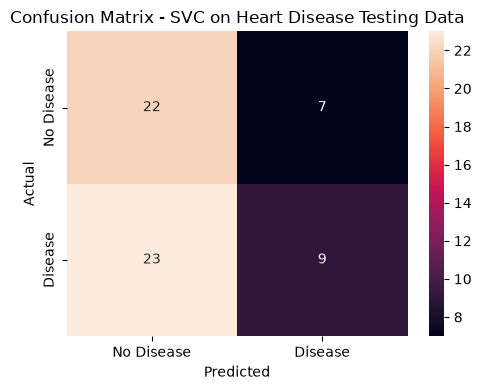

In [18]:
print("\nClassification Report:")
print("=======================\n")

print(classification_report(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"],
    target_names=["No Heart Disease", "Heart Disease"]
))

conf_matrix = confusion_matrix(
    testing_data_encoded["HeartDisease"],
    testing_data_encoded["Predictions"]
)

conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)

print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()


### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

The following example patient can be changed to test different combinations.

For the final Streamlit application, these same four attributes will be collected using input controls.


In [19]:
age_input = 55
sex_input = "Male"
cp_input = "Typical Angina"
thalach_input = 150

print(
    f"Age: {age_input}, "
    f"Sex: {sex_input}, "
    f"Chest Pain Type: {cp_input}, "
    f"Maximum Heart Rate: {thalach_input}"
)


Age: 55, Sex: Male, Chest Pain Type: Typical Angina, Maximum Heart Rate: 150


### Step 8.2: Convert User Input into Feature Vector

In [20]:
user_input = pd.DataFrame({
    "age": [age_input],
    "sex": [sex_input],
    "cp": [cp_input],
    "thalach": [thalach_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

   age   sex              cp  thalach
0   55  Male  Typical Angina      150


### Step 8.3: Label Encoding of Feature Vector

In [21]:
unseen_data_features = user_input.copy()

unseen_data_features["sex"] = sex_label_encoder.transform(
    unseen_data_features["sex"]
)

unseen_data_features["cp"] = cp_label_encoder.transform(
    unseen_data_features["cp"]
)

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   age  sex  cp  thalach
0   55    1   3      150


### Step 8.4: Load the Saved Model

In [22]:
model = pickle.load(
    open("heart_disease_svc_model.pkl", "rb")
)

print("Model loaded from heart_disease_svc_model.pkl")


Model loaded from heart_disease_svc_model.pkl


### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model and Return Prediction to the User

In [23]:
predicted_heart_disease = model.predict(
    unseen_data_features
)

if predicted_heart_disease[0] == 1:
    prediction = "HEART DISEASE PRESENT"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column(
    "       ** Prediction **       ",
    [prediction]
)

print(pretty_table)


+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|        NO HEART DISEASE        |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts

This is a worked example, following the same purpose as the supplied Titanic notebook. It is not a medical diagnosis and should not be interpreted as clinical validation.


In [24]:
example_feedback = pd.DataFrame({
    "Reviewer": [
        "Student Tester",
        "Student Tester",
        "Model Review"
    ],
    "Case": [
        "Patient with selected input values producing a disease prediction",
        "Patient with selected input values producing a no-disease prediction",
        "Testing set evaluation"
    ],
    "Feedback": [
        "The application correctly accepts the four required attributes and returns a prediction.",
        "The application returns a binary prediction using the saved trained model.",
        "Accuracy, precision, recall, F1-score and confusion matrix should be reviewed together."
    ]
})

print(example_feedback.to_string(index=False))


      Reviewer                                                                 Case                                                                                 Feedback
Student Tester    Patient with selected input values producing a disease prediction The application correctly accepts the four required attributes and returns a prediction.
Student Tester Patient with selected input values producing a no-disease prediction               The application returns a binary prediction using the saved trained model.
  Model Review                                               Testing set evaluation  Accuracy, precision, recall, F1-score and confusion matrix should be reviewed together.


#### Step 9.2: Make a List of Potential Improvements

In [25]:
improvements = [
    "Use additional permitted experiments with different four-feature selections and compare performance.",
    "Use a larger and more representative heart disease dataset for better generalization.",
    "Use cross-validation instead of relying on a single train-test split.",
    "Compare SVC with other classification algorithms.",
    "Use a preprocessing pipeline so encoding and model prediction are handled together.",
    "Collect feedback from qualified domain experts before considering real-world clinical use."
]

for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")


1. Use additional permitted experiments with different four-feature selections and compare performance.
2. Use a larger and more representative heart disease dataset for better generalization.
3. Use cross-validation instead of relying on a single train-test split.
4. Compare SVC with other classification algorithms.
5. Use a preprocessing pipeline so encoding and model prediction are handled together.
6. Collect feedback from qualified domain experts before considering real-world clinical use.


#### Step 9.3: Improve the Model Based on Feedback

In [26]:
print(
    "Next version: evaluate alternative four-feature combinations, "
    "compare models using cross-validation, and retrain the selected model "
    "before replacing the deployed version."
)


Next version: evaluate alternative four-feature combinations, compare models using cross-validation, and retrain the selected model before replacing the deployed version.


## Step 10: Deploy Your Model as a Public Streamlit Web App

The assignment requires the trained model to be deployed as a live Streamlit application.

### Step 10.1: Create the Project Folder

Your final deployment folder should contain:

```text
Heart-Disease-Prediction/
│
├── Heart_Disease.csv
├── heart_disease_svc_model.pkl
├── app.py
├── requirements.txt
└── Heart_Disease_Prediction.ipynb
```

### Step 10.2: GitHub

Create a GitHub repository and upload the required project files.

Do **not** upload unnecessary files such as your virtual environment folder.

### Step 10.3: Streamlit App

Create `app.py` using the same four inputs used in this notebook:

- Age
- Sex
- Chest Pain Type
- Maximum Heart Rate

The app should load `heart_disease_svc_model.pkl`, encode the categorical inputs using the same encoding used during training, and call the SVC model.

### Step 10.4: Requirements

Your `requirements.txt` should include the libraries used by the Streamlit application, such as:

```text
streamlit
pandas
numpy
scikit-learn
```

### Step 10.5: Deploy on Streamlit Community Cloud

1. Push the project to GitHub.
2. Open Streamlit Community Cloud.
3. Create a new app.
4. Select your GitHub repository.
5. Select the branch containing the project.
6. Set the main file to `app.py`.
7. Deploy the app.
8. Test the live prediction form.

### Step 10.6: Update the Deployment Link

After deployment succeeds, replace the placeholder at the top of this notebook:

`PASTE YOUR STREAMLIT LIVE LINK HERE`

with your actual Streamlit URL.

### Step 10.7: Final Check

Before submission, confirm that:

- the notebook runs from top to bottom;
- exactly four input attributes are used;
- the trained `.pkl` model exists;
- the dataset is included;
- `app.py` works;
- `requirements.txt` is included;
- the Streamlit link is publicly accessible;
- the live link is at the very top of this notebook;
- the notebook contains the evaluation results;
- the files uploaded to Google Classroom are the final versions.


## Conclusion

This system uses the UCI Heart Disease Cleveland dataset to build a binary heart disease prediction model. Four input attributes — age, sex, chest pain type, and maximum heart rate — are used to satisfy the assignment constraint. The data is pre-processed, categorical attributes are label encoded, an SVC model is trained and saved, testing metrics are calculated, and the trained model is prepared for deployment through a Streamlit web application.

**Important:** This is an academic machine learning project. The model is not a medical diagnostic system and should not be used to make clinical decisions.
